# Rapport : Estimation de modèles spatio-temporels par deep learning 

MIA Paris Saclay - Centre de Géosciences Mines Paris - Vincent Fourmigué


# Déroulement du stage

J'ai réalisé mon stage de deuxième année (M1) sur trois mois entre juin et aôut 2024, entre le laboratoire de Géostatistique des Mines de Paris et le laboratoire MIA de Mathématiques et Informatique Appliquées à l'INRAE. J'ai travaillé dans une jeune équipe très conviviale composée de Lucia CLAROTTO (AgroParisTech), Mike PEREIRA (Mines PSL) et Thomas ROMARY (Mines PSL).
<br>
<br>
Lors du stage j'ai pu avoir accès à pleins de ressources éducatives de différents types : cours sur le logiciel de version GIT, conférence sur les données sur grahes, séminaire de l'équipe de mathématiques appliquée, notebook d'introduction au graphe bi-partite sur PyG etc.


# Sujet du stage

## Mise en contexte : Géostatistique
On a des données spatialisées, ayant des
coordonnées $(x,y)$ en plus de leurs valeurs.
On les modélise selon un champs aléatoire Gaussien de
Matérn $Z$ de paramètres $\theta = (\nu,\rho,\sigma)$.
<br>

Cela signifie que $Z$ est un processus Gaussien de moyenne nulle et que sa fonction de covariance, définie pour toute distance $h$ entre un point $(x,y)$ et un point $(x',y')$, telle que $h=\sqrt{(x-x')^2+(y-y')^2}$, est égale à

$$C(h) = \frac{\sigma^2}{2^{\nu-1}\Gamma(\nu)}\left(\frac{h}{\rho}\right)^\nu \mathcal{K}_\nu\left(\frac{h}{\rho}\right)$$ 

où $\mathcal{K}_\nu$ est la fonction de Bessel de seconde type d'ordre $\nu$.

Usuellement, pour estimer les paramètres $\theta$, on maximise la vraisemblance 
ce qui nous pousse à inverser la matrice de covariance, calculée entre tous les points $\{(x_i,y_i)\}_{i=1:n}$. La complexité est alors de $\mathcal{O}(n^3)$ operations ($n$ étant le nombre de localisation spatiales), ce qui rend le processus impossible pour un grand $n$.

### Inférence amortie
En constatant qu'on sait simuler de manière peu couteuse des réalisations de champs de Matérn selon des paramètres choisis (donc créer un jeu d’entrainement de processus de Matérn), on imagine pouvoir estimer les paramètres $\theta$ à partir de ce jeu d'entrainement par apprentissage supervisé.  

On choisit une méthode d'apprentissage basée sur des réseaux de neurones (NN).

Une fois le NN entraîné, l'estimation de $\theta$ est instantanée. On parle alors d'inférence amortie.



### Quelle architecture pour le NN?
Si les données sont sur grille, CNN (Sainsbury-Dale et al., 2023)
<br>
Si les données sont éparses, GNN (Sainsbury-Dale et al., 2024)
<br>
Si les données sont spatio-temporelles ? ...

### Le type de données 

Les données d’entrainements sont des échantillons de champs Gaussien de Matérn choisis selon un processus ponctuel sur le domaine spatial (double processus de Poisson).
<br>
Cet échantillon de points est étiqueté avec les paramètres $\theta$ ayant permis la simulation.
<br>
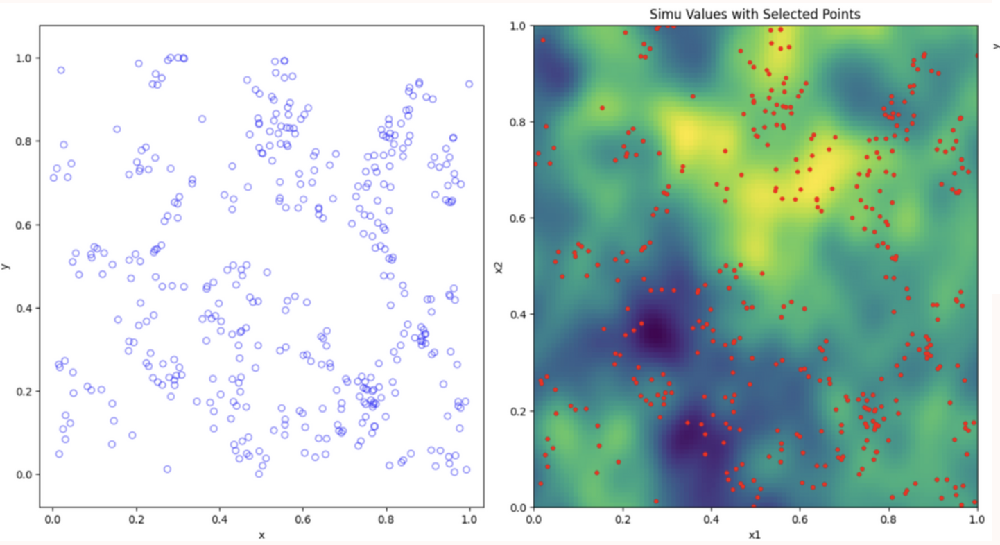
<br>




## Données spatiales vue comme un graphe dans le cas d'un GNN
On réalise un graphe à partir de ces points qui deviennent alors les noeuds du graphe.
<br>
Ne sont reliés que les points qui sont à une distance infèrieure à un seuil.
<br>
Le poids des arrêtes dépend la distance entre les points.
<br>
<br>
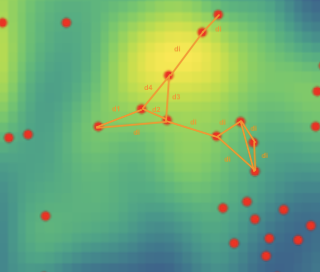

### Spécification du voisinage
Le voisinage de chaque point est défini lors de la création du graphe et a lieu après le double processus ponctuel.
<br>
Deux points ne sont reliés que si ils se situent à une distance infèrieure à un certain seuil.
<br>
A ce seuil de distance s'ajoute un autre seuil, qui définit le nombre maximal de voisins que chaque point peut avoir ; si un point a plus de voisins que le seuil, ses voisins sont tirés au hasard.

## Description générale du modèle issu du papier Sainsbury-Dale et al. (2023)

Sainsbury-Dale, M., Richards, J., Zammit-Mangion, A., & Huser, R. (2023). Neural bayes estimators for irregular spatial data using graph neural networks. arXiv preprint arXiv:2310.02600.


L'architecture du NN choisie pour l'estimation des paramètres des champs spatiaux de Matérn est celle proposée dans Saisbury-Dale et al. (2023) et détaillée ci-dessous.

Le modèle est un modèle de convolution sur graphes qui est constitué de plusieurs modules consécutifs :
<br>
- Le module de **propagation** qui effectue les convolutions sur graphes.
<br>
- Le module **readout** qui effectue un pooling sur les poids des noeuds d'un graphe et ressort un vecteur *R* nommé *summary statistics*, de taille 20.
<br>
- Le module de **mapping** qui est constitué d'un Multi-Layer Perceptron (MLP) simple qui fait le lien entre le vecteur de taille 20 sorti du module readout et un vecteur $\theta$ qui a pour taille le nombre de paramètres que l'on cherche à estimer dans le champ de Matèrn. 

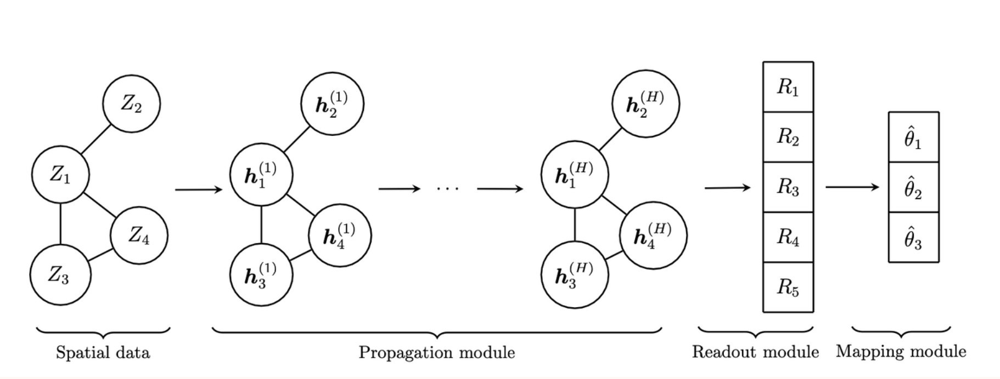
<br>


### Description détaillée du module de Propagation - Message Passing et coeur de GNN

Lors d'une convolution sur graphe, le **message passing** est le processus qui gère l'évolution des poids des noeuds et/ou des arêtes en fonction du voisinage.

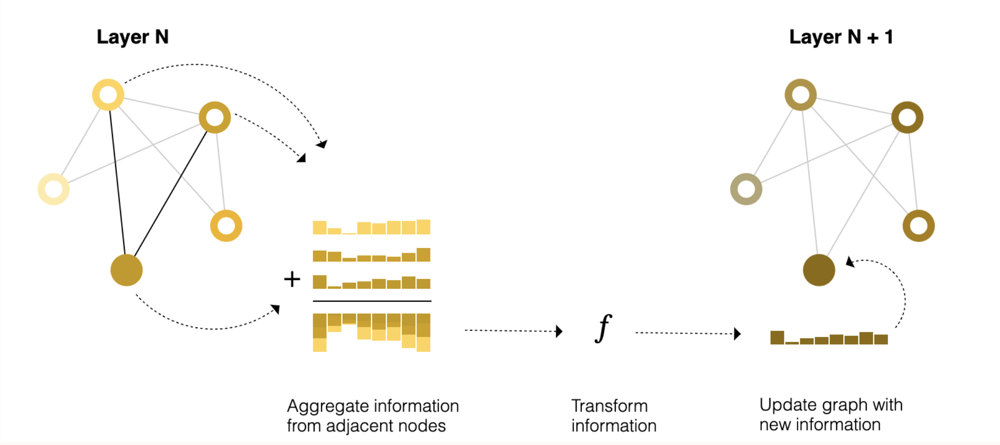
<br>

<br>
Dans le code proposé lors de mon stage, un module de propagation ou une couche de convolution sur graphe est composée de la succesion de deux classes Python, décrites ici et disponibles plus bas dans la section 2.3 relative au code.

- D'abord la class *Couchewtilde* transforme tous les attributs des arêtes pour qu'ils soient utilisables lors du message passing. 
- Puis la class *SpecialConv* effectue le message passing avec la fonction *propagate* et ensuite réalise la transformation (4) avec le résultat du message passsing qui est *hbar*.

Ce message passing ou cette façon d'actualiser le poids des noeuds d'un graphe prend en compte le poids des noeuds voisins à la couche précédente (*hjprime*) ainsi que le poids à la couche précédente du noeud en question (*hj*) mais aussi le poids spécifiquement attribués aux arrêtes (*wtilde*). 
<br>
Le détail est à retrouver autour de la définition de la fonction *SpecialConv*.
<br>
<br>

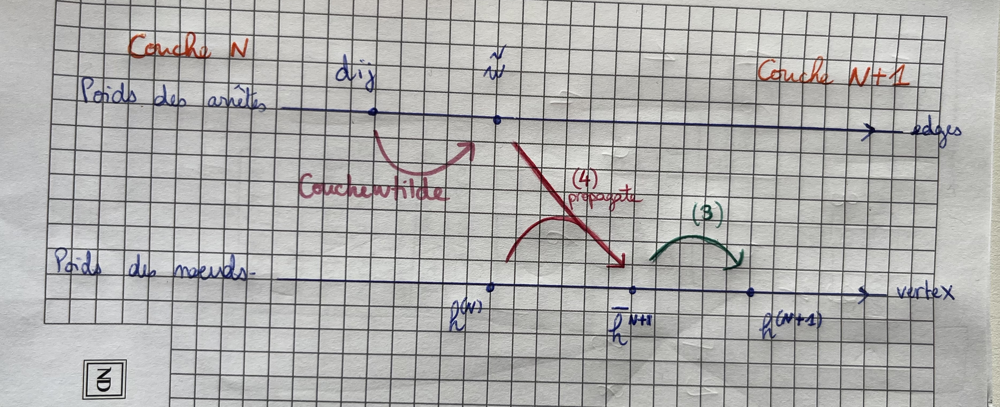

<br>
<br>

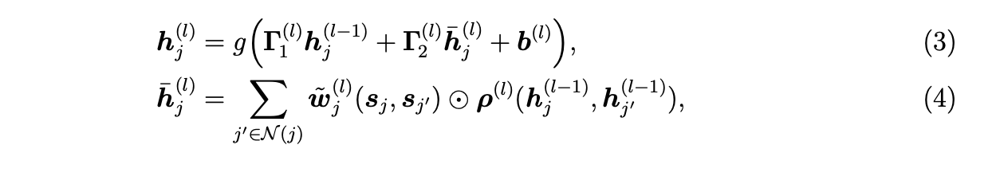

### Particularité de la vision globale des données : utilisation d'un DEEPSET

Zaheer, M., Kottur, S., Ravanbakhsh, S., Poczos, B., Salakhutdinov, R. R., and Smola, A. J. (2017). Deep sets. In Proceedings of the 31st Conference on Neural Information Processing Systems,

Dans le modèle complet d'inférence amortie Sainsbury-Dale et al. (2023) proposent une architecture **DeepSets** (Zaheer et al., 2017), qu'on ajoute aussi à notre modèle.

L'idée de cette architecture lors de l'entraînement est de rajouter plusieurs réalisation de champs de Matèrn différents mais ayant en commun les paramètres que l'on cherche à estimer.

On réalise ensuite un pooling sur les *R* (vecteurs de summary statistics) issus des $m$ graphes qui partagent les mêmes paramètres.


L'architecture DeepSet n'impacte que le début de notre structure.

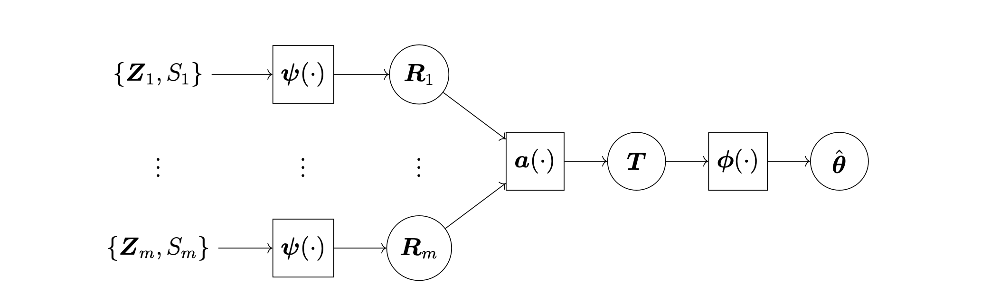

Cependant cette architecture est responsable de la vision que l'on a des données :

- On considère desormais une donnée comme un graphe composé de $m$ composantes non connexes et étiquetées par les paramètres $y=\theta$ que l'on cherche à estimer : $m=$ *deepset_size*.
- Cette donnée se verra attibuer un attribut de graphe global T (*Data.T*), qui sera simplement une liste de longueur $m$ contenant le nombre de noeuds pour chaque graphe. 
- Cet attribut est essentiel pour les poolings qui auront lieu dans la suite du modèle (le module **readout** du papier).
- Dans la fonction *train* définissant l'apprentissage T se déclinera en T1 et T2 qui permettront respectivement de faire le readout sur tous les noeuds du graphe appartenant au même sous-graphe (T1), puis de faire le pooling sur tous les *R* issus de chaque sous-graphe (T2).

Si l'utilisation de T1 et T2 ne semble pas nécessairement utile pour un seul graphe avec $m$ sous-graphes, il faut savoir que, en utilisant le loader de pytorch_geometric, tous les graphes d'un même batch seront fusionnés en un seul graphe avec ( *batch_size* x *deepset_size* ) sous-graphes.


L'explication ci dessus peut être accompagnée de l'annexe 1 se trouvant en bas du notebook.

### Tentative de représentation de l'architecture globale du modèle
<br>
<br>

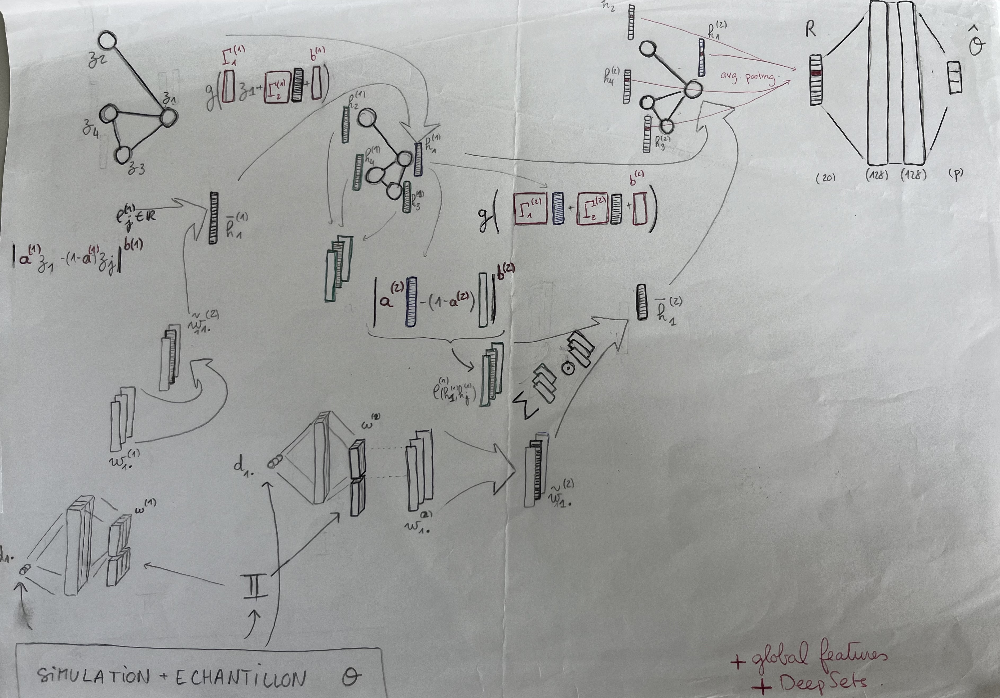


## Développement du code

### Librairies

In [378]:
import matplotlib
import matplotlib.pyplot as plt

import numpy as np
import pandas as pd

import random
from tqdm import tqdm
import time

In [11]:
import torch
import torch.nn as nn

import torch_geometric
from torch_geometric.data import Data
from torch_geometric.nn import global_mean_pool

from torch_geometric.data import Dataset
from torch_geometric.loader import DataLoader
from torch_geometric.data import Batch

from torch_geometric.utils import to_scipy_sparse_matrix
from torch_geometric.nn.conv import MessagePassing
from torch_geometric.utils import scatter
from torch_geometric.nn import aggr

C:\Users\alexo\PycharmProjects\Neural_ST_inference\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [206]:
from scipy.sparse.csgraph import connected_components
from scipy.spatial import cKDTree

In [12]:
import gstlearn as gl
import gstlearn.plot as gp
import gstlearn.document as gdoc
gdoc.setNoScroll()


<IPython.core.display.Javascript object>

In [13]:

device = torch.device("cuda:1" if torch.cuda.is_available() else "cpu")


In [14]:
torch_geometric.__version__

'2.7.0'

### Fonctions pour la création des données

Dans les sous-sections suivantes on décrit les fonctions nécessaires pour la création du jeu de données d'entraînement, i.e., les échantillons de champs Gaussiens de Matérn à des localisations éparses choisis selon un processus de double Poisson.

#### MaterPointProcess_0_99

- Simule un double procédé de poisson d'abord sur la fenetre carrée etendue puis sur un cercle 
- Return un dataframe panda avec deux colonnes pour les coordonnées des points   

[Ici plus de détails](https://hpaulkeeler.com/simulating-a-matern-cluster-point-process/)

Tous les échantillons créés avec les mêmes paramètres d'entrée pourront être de tailles différentes

In [567]:
#![returnmaternPP.png](attachment:a1126987-e79c-4922-8ea6-781f6188ec87.png)

In [568]:

def MaterPointProcess_0_99(lambdaParent,lambdaDaughter,radiusCluster,plot=False):

    # Simulation window parameters
    xMin = 0;
    xMax = 1;
    yMin = 0;
    yMax = 1;

    # lambdaParent = 10;  # density of parent Poisson point process
    # lambdaDaughter = 100;  # mean number of points in each cluster
    # radiusCluster = 0.1;  # radius of cluster disk (for daughter points)

    # Extended simulation windows parameters
    rExt = radiusCluster;  # extension parameter -- use cluster radius
    xMinExt = xMin - rExt;
    xMaxExt = xMax + rExt;
    yMinExt = yMin - rExt;
    yMaxExt = yMax + rExt;

    # rectangle dimensions
    xDeltaExt = xMaxExt - xMinExt;
    yDeltaExt = yMaxExt - yMinExt;
    areaTotalExt = xDeltaExt * yDeltaExt;  # area of extended rectangle

    # Simulate Poisson point process for the parents
    numbPointsParent = np.random.poisson(areaTotalExt * lambdaParent);  # Poisson number of points
    
    # x and y coordinates of Poisson points for the parent
    xxParent = xMinExt + xDeltaExt * np.random.uniform(0, 1, numbPointsParent);
    yyParent = yMinExt + yDeltaExt * np.random.uniform(0, 1, numbPointsParent);

    # Simulate Poisson point process for the daughters (ie final poiint process)
    numbPointsDaughter = np.random.poisson(lambdaDaughter, numbPointsParent); # np.random.poisson(lambdaDaughter*np.pi*((radiusCluster)**2), numbPointsParent);
    #l'aire du cercle étant <1 cela nuit gravement au résultat à utiliser en fonction des valeurs des paramètres
    numbPoints = sum(numbPointsDaughter);

    # Generate the (relative) locations in polar coordinates by
    # simulating independent variables.
    theta = 2 * np.pi * np.random.uniform(0, 1, numbPoints);  # angular coordinates
    rho = radiusCluster * np.sqrt(np.random.uniform(0, 1, numbPoints));  # radial coordinates
    # Convert from polar to Cartesian coordinates
    xx0 = rho * np.cos(theta);
    yy0 = rho * np.sin(theta);

    # replicate parent points (ie centres of disks/clusters)
    xx = np.repeat(xxParent, numbPointsDaughter);
    yy = np.repeat(yyParent, numbPointsDaughter);

    # translate points (ie parents points are the centres of cluster disks)
    xx = xx + xx0;
    yy = yy + yy0;

    # thin points if outside the simulation window
    booleInside = ((xx >= xMin) & (xx <= xMax) & (yy >= yMin) & (yy <= yMax));
    # retain points inside simulation window
    xx = xx[booleInside];
    yy = yy[booleInside];

    # keeping the same digits precision as the simtub
    data = {'x1': xx, 'x2': yy}
    echantillon = pd.DataFrame(data)
    #echantillon = echantillon.astype(int)

    return(echantillon)

####  créer_edge_graph

- Prend en entrée un dataframe avec les coordonnées et la valeur prise par la réalisation pour chaque point

- Créé un graphe afin que le nombre maximum de voisins en tout point soit *max_neighbors* et que deux points soient voisins s'ils sont situés moins loin que *threshold*

- Met la distance entre les deux sommets de l'arête en attribut d'arête (*edge_attr*) pour chaque point

- Return le graphe

In [569]:
def creer_edge_graph(echantillon, threshold, max_neighbors):
    coords = echantillon[['x1', 'x2']].values
    node_features = torch.tensor(echantillon[['Simu']].values, dtype=torch.float)

    nearest_neighbors = cKDTree(coords) 

    edge_sources = []
    edge_destinations = []
    edge_features = []

    for i, coord in enumerate(coords):
        neighbors = nearest_neighbors.query_ball_point(coord, r=threshold)
        neighbors = [j for j in neighbors if j != i]

        if len(neighbors) > max_neighbors:
            neighbors = np.random.choice(neighbors, max_neighbors, replace=False)

        dists = np.linalg.norm(coords[neighbors] - coord, axis=1)
            
        edge_sources.extend(np.repeat(i,len(neighbors))) # [i] * len(neighbors)
        edge_destinations.extend(neighbors) # neighbors.tolist()

        edge_sources.extend(neighbors)
        edge_destinations.extend(np.repeat(i,len(neighbors)))
        
        edge_features.extend(np.concatenate([dists, dists]))

    edge_index = torch.tensor([edge_sources, edge_destinations], dtype=torch.long)
    edge_attr = torch.tensor(edge_features, dtype=torch.float).unsqueeze(1) # .view(-1, 1)

    return Data(x=node_features, edge_index=edge_index, edge_attr=edge_attr)


####  simu_echantillonage_graph

* Crée un graphe selon ce process :

1. Réalise le Matern Point Process pour extraire les coordonnées des points du graphe
<br>
2. Ajoute une colonne *Simu* au dataframe contenant la réalisation de Matern en chaque point
<br>
3. Utilise *créer_edge_graph* pour faire le graphe avec la valeur de *Simu* en node attribute et la distance entre deux points en *edge attribute*
<br>

- Return un graphe avec une seule composante, et dont tous les points sont reliés

In [570]:
gl.Db_fromPandas(pd.DataFrame({'x1':np.repeat(np.linspace(0,1,100),100),'x2':np.tile(np.linspace(0,1,100),100)}))[0]

array([0., 0., 0., ..., 1., 1., 1.], shape=(10000,))

In [571]:

def simu_echantillonage_graph(range,param_model,lambdaParent,lambdaDaughter,radiusCluster,threshold,max_neighbors):

    echantillon_a=MaterPointProcess_0_99(lambdaParent,lambdaDaughter,radiusCluster,plot=False)#(100,50,0.10,False)
    db = gl.Db_fromPandas(echantillon_a)
    db.setLocators(["x1","x2"],gl.ELoc.X)

    # BESSEL_K -> MATERN
    model = gl.Model.createFromParam(type=gl.ECov.MATERN, range = range*np.sqrt(8), param = 1, sill = param_model**2)  # range is the practical range of Matérn with smoothness parameter = 1
    err = gl.simtub(None, db, model, None, nbsimu=1, seed=0, nbtuba = 1000) #seed=0 lance à chaque fois une simu différente
    #err = gl.Model.addCovFromParam(model,type=gl.ECov.NUGGET, sill = 1) ##Ajouter un nugget de variance 1

    df=pd.DataFrame({'Simu': db['z1']})
    echantillon_a = pd.concat([echantillon_a, df],axis=1)
    #print(echantillon_a)
    data=creer_edge_graph(echantillon_a,threshold,max_neighbors) #threshold=0.4 max_neighbors=10

    # db_heatmap = gl.Db_fromPandas(pd.DataFrame({'x1':np.repeat(np.linspace(0,1,100),100),'x2':np.tile(np.linspace(0,1,100),100)}))
    # db_heatmap.setLocators(["x1","x2"],gl.ELoc.X)
    # err = gl.simtub(None, db_heatmap, model, None, nbsimu=1, seed=0, nbtuba = 1000)

    if False:
            # Plotting
            fig, axs = plt.subplots(1, 1, figsize=(14, 7), constrained_layout=True)

            #axs.scatter(echantillon_a['x1'], echantillon_a['x2'], c=echantillon_a['Simu']) 
            axs.scatter(db_heatmap[0], db_heatmap[1], c=db_heatmap['z1'],s=10) 
        
            axs.set_xlabel('x1')
            axs.set_ylabel('x2')
            axs.set_title('Simu Values with Selected Points')

            axs.set_xlim([0, 1])
            axs.set_ylim([0, 1])
            axs.axis('equal')

            plt.show()

    
    return(data)


#### merge_components

- Prend en entrée une liste de $m$ (*deepset_size*) graphes

- Fusionne tous les graphes d'un même Deepset en un seul graphe à $m$ composantes non connexes

- Rajoute au graphe fusionné un attribut global *T*, qui contient le nombre de noeuds de chaque sous graphe

Cette fonction est cruciale pour la création du jeu de données puisque elle s'assure que tous les graphes qui sont "fusionnés" au sein d'un graphe à composantes non connexes ont des indices de noeuds et d'arrêtes qui sont tous distincts.


In [572]:

def merge_components(components,deepset_size):
    x_list = []
    edge_index_list = []
    edge_attr_list = []
    num_nodes_offset = 0
    i=0
    T=torch.empty(deepset_size)
    D=[]
    for component in components:
                
        component.edge_index,component.edge_attr = torch_geometric.utils.coalesce(component.edge_index,component.edge_attr,reduce='mean', is_sorted=True)
        x_list.append(component.x)
        edge_index_list.append(component.edge_index + num_nodes_offset)  # Ajuster les indices des arêtes
        edge_attr_list.append(component.edge_attr)
        num_nodes_offset += component.num_nodes
        T[i]=component.num_nodes
        #D+=(component.d)
        i+=1
    x = torch.cat(x_list, dim=0)
    edge_index = torch.cat(edge_index_list, dim=1)
    #edge_attr_list = torch.tensor(edge_attr_list, dtype=torch.float)
    #print(edge_attr_list)
    edge_attr = torch.cat(edge_attr_list, dim=0)
    graph = Data(x=x, edge_index=edge_index,edge_attr1=edge_attr)# edge_attr=edge_attr)
    graph.T=T
    return graph


####  simu_graph

- Crée un gros graphe avec *deepset_size* composantes non connexes selon les paramètres d'une réalisation de Matérn

- Ajoute au graphe le target *data.y* contenant les deux paramètres de la fonction de Matérn que l'on cherche à estimer


In [573]:

def simu_graph(deepset_size, range_val, param_model, lambdaParent, lambdaDaughter, radiusCluster, threshold, max_neighbors):
    data = [simu_echantillonage_graph(range_val, param_model, lambdaParent, lambdaDaughter, radiusCluster, threshold, max_neighbors) for i in range(int(deepset_size))]
    data=merge_components(data,deepset_size)
    data.y=torch.log(torch.tensor((range_val,param_model)))
    
    return data


####  composante_non_connexes

- Calcule le nombre de composantes non connexes d'un graphe (fonction de vérification)

In [574]:

def composante_non_connexes(data):
    adj_matrix = to_scipy_sparse_matrix(data.edge_index)
    num_components, labels = connected_components(adj_matrix, directed=False)
    print(f"Le graphe contient {num_components} composante(s) connexe(s).")
    return(num_components)

####  datamaker

- Crée le jeu de données avec *n* graphes composés chacun de *deepset_size* sous graphes

Les listes *L* et *M* sont utilisées dans la phase de test pour un modèles où $n=4$ ou moins

In [580]:


#L=[0.3,0.3,0.5,0.5]
#M=[0.7,0.7,0.5,0.5]
#L=[(0.3) for i in range(10)]+[(0.5) for i in range(10)]
#M=[(0.7) for i in range(10)]+[(0.5) for i in range(10)]


def datamaker(constant_product,n,deepset_size):

    
    datalist=[]
    range_list = np.random.uniform(0.05,0.4,n)
    variance_list = np.random.uniform(0.1,1.,n)
    lambdaParent = np.random.uniform(10, 30,n)
    lambdaDaughter = constant_product / lambdaParent
    
    for i in range(n): 
        
        datalist.append(simu_graph(deepset_size,range_list[i],variance_list[i],lambdaParent[i],lambdaDaughter[i],0.10,0.4,10))         
        
        # pour les exemples de check avec des valeur de y qui sont fixées par les listes L et M
        #datalist.append(simu_graph(deepset_size,L[i],M[i],lambdaParent[i],lambdaDaughter[i],0.10,0.4,10))         

    print(f" Generated dataset size: {n * deepset_size}")
    
    return datalist


### Création effective des données

In [582]:
constant_product=400
n=20
deepset_size=5
datalist=datamaker(constant_product,n,deepset_size)

 Generated dataset size: 100


In [583]:
datalist

[Data(x=[1972, 1], edge_index=[2, 19681], edge_attr1=[19681, 1], T=[5], y=[2]),
 Data(x=[2072, 1], edge_index=[2, 20833], edge_attr1=[20833, 1], T=[5], y=[2]),
 Data(x=[2531, 1], edge_index=[2, 25166], edge_attr1=[25166, 1], T=[5], y=[2]),
 Data(x=[1642, 1], edge_index=[2, 16442], edge_attr1=[16442, 1], T=[5], y=[2]),
 Data(x=[2171, 1], edge_index=[2, 21746], edge_attr1=[21746, 1], T=[5], y=[2]),
 Data(x=[1898, 1], edge_index=[2, 19029], edge_attr1=[19029, 1], T=[5], y=[2]),
 Data(x=[1826, 1], edge_index=[2, 18248], edge_attr1=[18248, 1], T=[5], y=[2]),
 Data(x=[2112, 1], edge_index=[2, 21229], edge_attr1=[21229, 1], T=[5], y=[2]),
 Data(x=[1902, 1], edge_index=[2, 19010], edge_attr1=[19010, 1], T=[5], y=[2]),
 Data(x=[2344, 1], edge_index=[2, 23508], edge_attr1=[23508, 1], T=[5], y=[2]),
 Data(x=[1927, 1], edge_index=[2, 19301], edge_attr1=[19301, 1], T=[5], y=[2]),
 Data(x=[1941, 1], edge_index=[2, 19515], edge_attr1=[19515, 1], T=[5], y=[2]),
 Data(x=[1857, 1], edge_index=[2, 18545]

#### Création d'un dataset pytorch

In [357]:
class GraphSetDataset(Dataset):
    def __init__(self, datalist):
        self.datalist = datalist

    def __len__(self):
        return len(self.datalist)

    def __getitem__(self, idx):
        return self.datalist[idx]


#### Fonction *collate_fn* pour gérer l'assemblage des graphes lors du batching

Dans la même idée que *merge_components* on s'assure que tous les graphes qui sont "fusionnés" au sein d'un graphe à composantes non connexes ont des indices de noeuds et d'arrêtes qui sont tous distincts.

En effet lors du batching le loader de PyG fait des données (qu'il suppose être des graphes simples) d'un même batch un gros graphe à composantes non connexes.

In [358]:
def collate_fn(batch):

    x_list = []
    edge_index_list = []
    edge_attr_list = []
    num_nodes_offset = 0
    i=0
    labels = torch.empty(len(batch),2)
    
    for allset, label in batch:
        labels.append(label)
        x_list.append(allset.x)
        edge_index_list.append(allset.edge_index + num_nodes_offset)  # Ajuster les indices des arêtes
        edge_attr_list.append(allset.edge_attr)
        num_nodes_offset += allset.num_nodes


    x = torch.cat(x_list, dim=0)
    edge_index = torch.cat(edge_index_list, dim=1)
    edge_attr = torch.cat(edge_attr_list, dim=0)
    graph = Data(x=x, edge_index=edge_index, edge_attr=edge_attr)
    labels = torch.tensor( labels,dtype=torch.float32)

    return graph, labels

#### Mise en forme des données sous la forme d'un dataset puis de batchs

In [589]:
dataset = GraphSetDataset(datalist)

batch_size = 3

loader = DataLoader(dataset, batch_size, collate_fn=collate_fn, shuffle=True)

### Création du modèle

#### one_hot_encode_distance

- Prend en entrée *distance* et *threshold* (distance max entre deux voisins)

- Encode dans un tenseur de taille 10 auquel des 10 intervalles de *threshold* de taille égale appartient *distance*

La fonction sera appliquée à tous les *edges_attr*

In [360]:
def one_hot_encode_distance(threshold, distance, epsilon=1e-5):
    if distance < epsilon or distance > threshold:
        raise ValueError(distance,threshold,"Distance should be within the range (0, threshold]")
    
    interval_length = threshold / 10
    interval_index = int(distance / interval_length)
    if interval_index == 10:
        interval_index = 9
    
    one_hot = torch.zeros(10, device=device)
    one_hot[interval_index] = 1
    
    return one_hot

In [361]:
one_hot_encode_distance(0.4,0.34)

tensor([0., 0., 0., 0., 0., 0., 0., 0., 1., 0.])

In [362]:
class expact(nn.Module):
    def forward(self, x):
        return torch.exp(x)
        


In [363]:
class EdgeFeatureMLP(nn.Module):
    def __init__(self, input_dim, hidden_dim, edge_output_dim):
        super(EdgeFeatureMLP, self).__init__()
        self.mlp = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, edge_output_dim)
            #nn.Relu() #enlevé à checker
        ).to(device) 

    def forward(self, x):
        return self.mlp(x)
    

In [364]:
   
class MappingLayer(nn.Module):
    def __init__(self, input_dim, hidden_dim, output_dim):
        super(MappingLayer, self).__init__()
        self.mlp = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, output_dim)#,
            #expact()
            #enlever dans le cas où on s'intéresse desormais au log des  target classiques parametres kappa sigma à check
        )

    def forward(self, pooled_feature):
        device=pooled_feature.device
        out = self.mlp(pooled_feature.to(device))
        return out


In [365]:
class Couchewtilde(nn.Module):
    def __init__(self, in_channels, edge_hidden_dim, edge_output_dim, threshold):
        super(Couchewtilde, self).__init__()
        
        self.edge_mlp = EdgeFeatureMLP(in_channels, edge_hidden_dim, edge_output_dim)
        self.threshold = threshold
    
    def forward(self, data):

        x, edge_index, edge_attr1 = data.x.to(device), data.edge_index.to(device), data.edge_attr1.to(device)
        mlp_output = self.edge_mlp(edge_attr1)
        one_hot_features = torch.stack([one_hot_encode_distance(self.threshold, d.item()) for d in edge_attr1]).to(device) # ancienne version
        w = torch.cat((one_hot_features, mlp_output), dim=1)        
        d = scatter(w, edge_index[0],reduce = 'sum') #sum over all neighbors
        dtilde = d[edge_index[0]]  
        mask = dtilde != 0
        replacement_tensor = torch.full((1, 20), 1e-5, device=device)
        wtilde = torch.where(mask, w / dtilde, replacement_tensor)    
        data.edge_attrwtilde=wtilde
        
        return data

In [366]:
class SpecialConv(MessagePassing):  ## created from CGConv
    # in edge attribute there is d_ij and wtilde_ij forall i,j (2D Tensor)
    
    def __init__(self, hidden_channels, moovingvaluegamma1):
        super().__init__(aggr='add')
        self.a = nn.Parameter(torch.rand(1, device=device)) # a in [0, 1]
        self.b = nn.Parameter(torch.rand(1, device=device) + 1) # b > 0
        self.gamma1 = nn.Parameter(torch.rand(hidden_channels, moovingvaluegamma1, device=device))
        self.gamma2 = nn.Parameter(torch.rand(hidden_channels, hidden_channels, device=device))
        self.biax = nn.Parameter(torch.rand(hidden_channels,1, device=device))
    
    def forward(self, x: torch.Tensor, edge_index: torch.Tensor,
                edge_attr: torch.Tensor ) -> torch.Tensor:
        
        hbar = self.propagate(edge_index, x=x, edge_attr=edge_attr) ## vrai message passing
        
        hbar=hbar.transpose(1,0)
        x=x.transpose(1,0)
        
        out = self.gamma1 @ x + self.gamma2 @ hbar + self.biax
        out=out.transpose(1,0)
        out = torch.nn.ReLU()(out).squeeze()

        return out

    def message(self, x_i, x_j, edge_attr: torch.Tensor) -> torch.Tensor:
        
        rho = (torch.abs(self.a * x_i - (1 - self.a) * x_j)) ** self.b

        return rho * edge_attr


#### DeepTEST

Architecture globale contenant tous les modules (couches convolutives, readout et MLP)

In [367]:

class DeepTEST(nn.Module):

    def __init__(self, in_channels, moovingvaluegamma1_1, moovingvaluegamma1_2, hidden_dim, edge_hidden_dim, edge_output_dim, threshold,mapping_hidden_dim, final_output_dim):# final_output_dim, mapping_hidden_dim, threshold):
        super(DeepTEST, self).__init__()
        
        self.Coucheinitialewtilde = Couchewtilde(in_channels, edge_hidden_dim, edge_output_dim, threshold)
        self.specialconv1 = SpecialConv(hidden_dim,moovingvaluegamma1_1)
        
        self.Coucheinterwtilde = Couchewtilde(in_channels, edge_hidden_dim, edge_output_dim, threshold) # A répéter si on veut
        self.specialconv2 = SpecialConv(hidden_dim,moovingvaluegamma1_2)
        
        self.mapping = MappingLayer(hidden_dim, mapping_hidden_dim, final_output_dim)

    def forward(self, data):
        data = data.to(device)
        data_T=data.T.to(device)
        data_batch=data.T2.to(device)
        
        data = self.Coucheinitialewtilde(data)
        data.x = self.specialconv1(x=data.x, edge_index=data.edge_index, edge_attr= data.edge_attrwtilde)
        #print('postpremière couche',data)
        
        data=self.Coucheinterwtilde(data)
        data.x=self.specialconv2(x=data.x, edge_index=data.edge_index, edge_attr= data.edge_attrwtilde)
        #print('postdeuxieme couche',data)
        
        pooled_graphs = global_mean_pool(data.x, data_T) 
        #print('pooled_graphs',pooled_graphs)
        out=global_mean_pool(pooled_graphs, data_batch) 
        #print('out',out)
        output = self.mapping(out)
        output = output.view(-1)
        #print(output)
        return output

    
    


In [368]:
model = DeepTEST(in_channels=1,
                 moovingvaluegamma1_1=1,
                 moovingvaluegamma1_2=20 ,
                 hidden_dim=20,
                 edge_hidden_dim=128,
                 edge_output_dim=10,
                 threshold=0.40,
                 mapping_hidden_dim=128,
                 final_output_dim=2)
#in_channels=1, hidden_dim=20, edge_hidden_dim=128, edge_output_dim=10, final_output_dim=2, mapping_hidden_dim=128, threshold=0.40).to(device)

### Entraînement du modèle

In [369]:

optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)


def train(model, optimizer, loader, n, batch_size): #leave=False,):
    model.train()
    MAE = torch.nn.L1Loss(reduction="mean")
    sum_loss = 0.0
    total = n // batch_size
    #t = tqdm(enumerate(loader), total=total, leave=leave)
    t=enumerate(loader)
    for i, batched_data in t:
        optimizer.zero_grad()

        T1 = []
        for j in range(len(batched_data.T)):
            T1.extend([j] * int(batched_data.T[j].item()))  
        batched_data.T = torch.tensor(T1, device=device)

        T2=[]
        for w in range(len(batched_data)):
            T2.extend([w] * deepset_size)
        batched_data.T2 = torch.tensor(T2, device=device)

        batched_data.y = batched_data.y.view(batch_size, 2) 
        batched_data = batched_data.to(device)

        output = model(batched_data)
        output=torch.reshape(output,(batch_size,2))

        if output.size(0) != batch_size or output.size(1) != 2:
            raise ValueError(f"Expected output shape ({batch_size}, 2) but got {output.size()}")

        y_batch = batched_data.y.to(device)
        
        #print('model output train: ',output)
        #print('real y_batch train: ',y_batch)  ## ybatch est sur le log des parametres classique
        
        batch_loss = MAE(output, y_batch)
        
        # print('training...')
        batch_loss.backward()
        optimizer.step()

        sum_loss += batch_loss.item()
        #t.set_description(f"loss = {batch_loss.item():.5f}")
        #t.refresh()

    return sum_loss / (i + 1)



Epoch 20/20: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 20/20 [03:23<00:00, 10.18s/it, loss=0.5655]


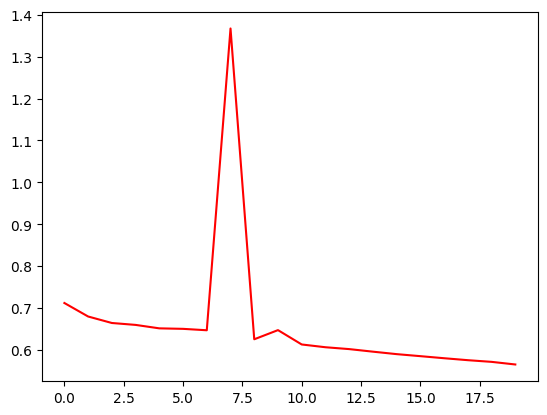

In [383]:
# Epoch loop
n_epochs = 20
Loss=[]
n = len(dataset)
#t = tqdm(enumerate(loader), total=total, leave=leave)



t = tqdm(range(0, n_epochs),total=n_epochs)

for epoch in t:
    
    loss = train(
        model,
        optimizer,
        loader,
        n,
        batch_size,
        #leave=(epoch == n_epochs - 1),
    )

    t.set_description(f"Epoch {epoch+1}/{n_epochs}")
    t.set_postfix(loss=f"{loss:.4f}")
    Loss.append(loss)




matplotlib.pyplot.plot(np.array(Loss), 'r')

# Résultats, perspectives et acquis lors du stage 

## Résultats et perspectives

Tout d'abord la reconstruction "from scratch" ou en partant de peu est en soit un résultat; initialement je n'avais à disposition que le code en Julia de l'auteur de l'article et les exemples de la bibliothèque PyG, sur d'autres modèles de convolution sur graphes.

Il est aussi à noter que la simulation des données est rapide comme l'entraînement du modèle. Les premiers résultats sont prometteurs et s'appuyent sur une architecture fonctionelle.


Pour s'assurer de l'efficacité de la méthode et de l'architecture adoptée, le code ci-dessus doit être testé sur des datasets plus conséquents que le jeu de données que j'ai créé et utilisé dans cet exemple.

On pourrait sauvegarder un grand nombre de simulations (calculées une suele fois au début) dans un fichier externe afin de les réutiliser pour tester les architectures et les hyperparamètres du modèles.


Si cette implémentation est satisfaisante, il faudrait tester la résistance du modèle avec des données spatio temporelles.
<br>
On peut pour cela dans un premier temps envisager un agrandissement du voisinage des points considérés lors de la convolution. Le nouveau voisinage serait alors spatio-temporel comme présentés ci-dessous.

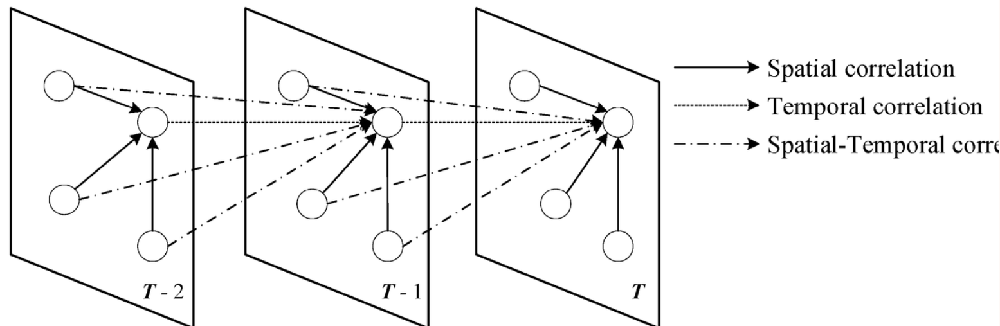

<br>
<br>

Le jeu de données considérerait alors une série discrète du même champ de Matèrn observés à plusieurs instants à la place dudit champ.
<br>
<br>

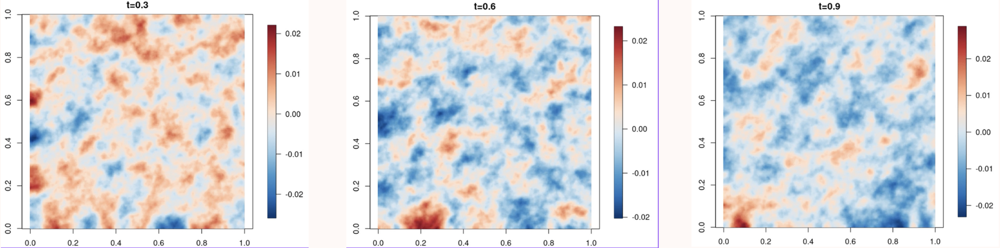




# ANNEXE 1
## Explication des attributs T1 et T2 via le code 

T1 et T2 sont nécessaires à cause de la structure du DeepSet

In [590]:
t = enumerate(loader)
for i, batched_data in t:
    print(i,batched_data)
    print('len(batched_data) taille des batch : ', len(batched_data))
    print('batched_data.T : ',batched_data.T)

    print('nombre de noeuds totaux',sum(batched_data.T))
    T1 = []
    for j in range(len(batched_data.T)):
        T1.extend([j] * int(batched_data.T[j].item()))  
    batched_data.T = torch.tensor(T1, device=device)
    #print('batched_data.T1',batched_data.T)
    print('len(batched_data.T) normalement de longueur égale au nombre de noeuds totaux par batch (tous deepsets confondus) : ',len(batched_data.T))
    print('De quelle simu fait partie chaque noeud, batched_data.T : ',batched_data.T)


    T2=[]
    for w in range(len(batched_data)):
        T2.extend([w] * deepset_size)
    batched_data.T2 = torch.tensor(T2, device=device)
    print('len(batched_data.T2) normalement de longueur égale au nombre de deepsets fois taille du batch : ',len(batched_data.T2))
    print('Dans quelle simu du batch fait partie chaque deepset, batched_data.T2 : ',batched_data.T2)

    data=model(batched_data)

    #print('data.edge_attrwtilde_45',data.edge_attrwtilde[45])
    #print('data.edge_attr1_45',data.edge_attr1[45])

    print('data',data)



    

0 DataBatch(x=[6387, 1], edge_index=[2, 63821], edge_attr1=[63821, 1], T=[15], y=[6], batch=[6387], ptr=[4])
len(batched_data) taille des batch :  3
batched_data.T :  tensor([509., 262., 289., 205., 377., 247., 413., 752., 537., 395., 410., 504.,
        421., 469., 597.])
nombre de noeuds totaux tensor(6387.)
len(batched_data.T) normalement de longueur égale au nombre de noeuds totaux par batch (tous deepsets confondus) :  6387
De quelle simu fait partie chaque noeud, batched_data.T :  tensor([ 0,  0,  0,  ..., 14, 14, 14])
len(batched_data.T2) normalement de longueur égale au nombre h :  15
De quel simu du batch fait partie chaque deepset, batched_data.T2 :  tensor([0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2])
data tensor([-7.5759, -6.3348, -1.4919, -1.3029, -2.4984, -2.1177],
       grad_fn=<ViewBackward0>)
1 DataBatch(x=[5982, 1], edge_index=[2, 59939], edge_attr1=[59939, 1], T=[15], y=[6], batch=[5982], ptr=[4])
len(batched_data) taille des batch :  3
batched_data.T :  tensor([42